# 1. Príprava dát

**Úloha:** z krátkeho videoklipu rozpoznať, ktorú činnosť človek vykonáva.
Zoznam tried je v `har/config.py` (`CLASSES`).

**Dáta:** HMDB51 – 51 činností, klipy z filmov a YouTube. Pôvodné videá sa prevedú na snímky
skriptom `convert_hmdb_videos.py` (postup je v jeho popise). Výsledná štruktúra:
`HMDB51/<trieda>/<klip>/<snímka>.jpg`.

V tomto notebooku:
1. vytvoríme zoznam klipov `index.csv`,
2. ukážeme delenie na trénovacie a testovacie dáta,
3. pozrieme sa na dĺžku klipov a ukážku snímok.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from har.config import CLASSES, DATA_DIR, INDEX_FILE
from har.data import read_frames
from har.evaluation import make_splits

## Zoznam klipov

Pre každý klip ukladáme:
- `path` – priečinok so snímkami klipu,
- `cls` – názov triedy, `label` – číslo triedy (poradie v `CLASSES`),
- `source` – film, z ktorého je klip vystrihnutý. Názov klipu v HMDB51 má tvar
  `<film>_<trieda>_<6 údajov o zázname>`, napr.
  `20060723sfjffdabaum_eat_h_cm_np1_fr_goo_0` → `20060723sfjffdabaum`.

In [2]:
rows = []
for label, cls in enumerate(CLASSES):
    for clip in sorted((Path(DATA_DIR) / cls).iterdir()):
        if clip.is_dir():
            source = clip.name.rsplit("_", 6)[0].removesuffix(f"_{cls}")
            rows.append({"path": str(clip), "cls": cls, "label": label, "source": source})

df = pd.DataFrame(rows)
df.to_csv(INDEX_FILE, index=False)
print("počet klipov:", df.cls.value_counts().to_dict())
print("počet filmov:", df.source.nunique())

počet klipov: {'clap': 130, 'eat': 108}
počet filmov: 90


## Delenie na trénovacie a testovacie dáta

Z jedného filmu býva vystrihnutých viac klipov s podobnými zábermi. Preto delíme dáta
**podľa filmu**: všetky klipy jedného filmu sú buď v trénovacích, alebo v testovacích dátach.

Každý model hodnotíme na **10 rôznych deleniach** (70 % trénovacie / 30 % testovacie dáta)
a uvádzame priemer a smerodajnú odchýlku cez delenia. Ukážka prvého delenia:

In [3]:
split, tr, te = next(make_splits(df))
train, test = df.iloc[tr], df.iloc[te]

print("filmy v trénovacích aj testovacích dátach:", len(set(train.source) & set(test.source)))
pd.DataFrame({"trénovacie": train.cls.value_counts(), "testovacie": test.cls.value_counts()})

filmy v trénovacích aj testovacích dátach: 0


,trénovacie,testovacie
cls,,
clap,98,32
eat,83,25


## Dĺžka klipov

Klipy majú rôzny počet snímok. Z každého klipu vyberáme 16 rovnomerne rozložených snímok,
takže vstup modelu má vždy rovnakú veľkosť.

In [4]:
df["n_frames"] = df.path.map(lambda p: len(list(Path(p).glob("*.jpg"))))
df.groupby("cls").n_frames.describe().round(1)

,count,mean,std,min,25%,50%,75%,max
cls,,,,,,,,
clap,130.0,77.6,47.4,24.0,55.2,78.0,78.0,379.0
eat,108.0,85.6,34.2,40.0,65.8,78.0,101.2,246.0


## Ukážka klipov

16 snímok vybraných z prvého klipu každej triedy – takto vyzerá vstup modelov.

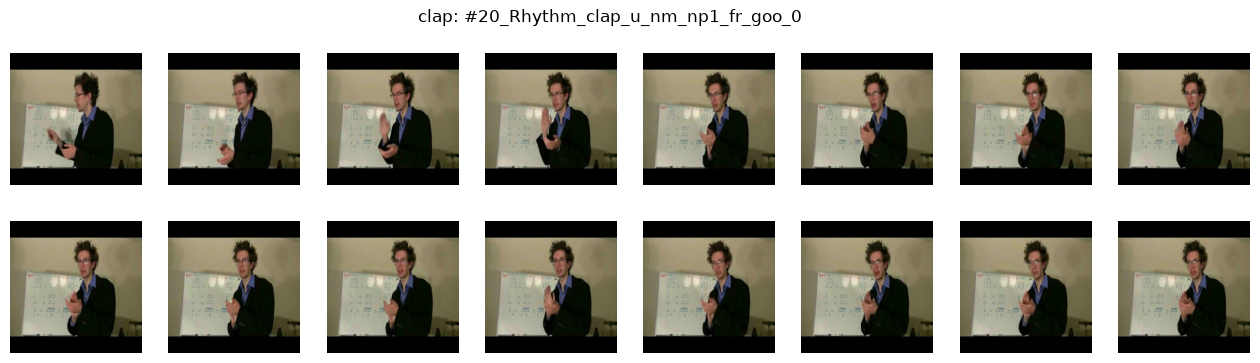

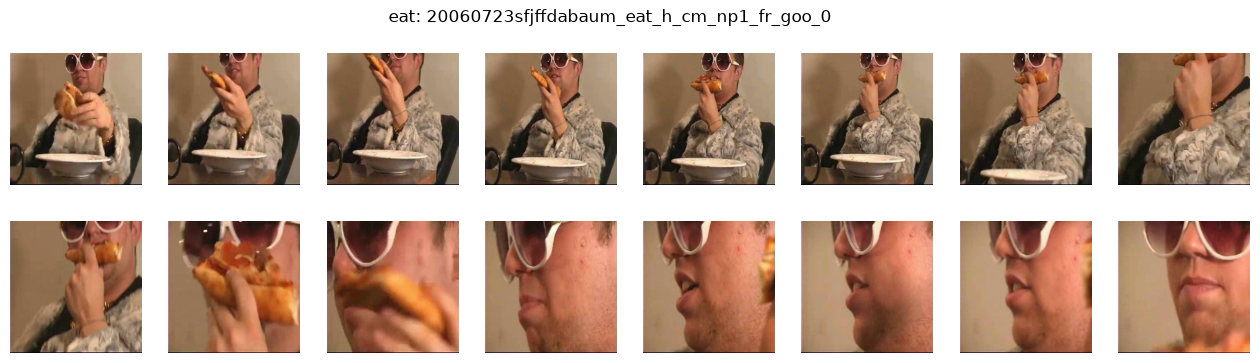

In [5]:
for cls, g in df.groupby("cls"):
    frames = read_frames(g.path.iloc[0])            # (16, 224, 224, 3)
    fig, axes = plt.subplots(2, 8, figsize=(16, 4))
    for ax, frame in zip(axes.flat, frames):
        ax.imshow(frame)
        ax.axis("off")
    fig.suptitle(f"{cls}: {Path(g.path.iloc[0]).name}")
    plt.show()